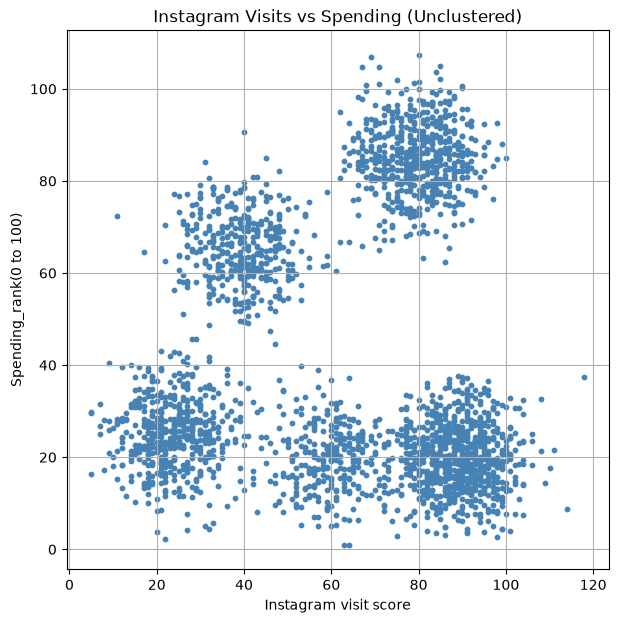

In [5]:
import matplotlib.pyplot as plt
import pandas as pd

df = pd.read_csv('ig_clustering.csv', index_col='User ID')
X_raw = df.to_numpy(dtype=float)

plt.figure(figsize=(7, 7))
plt.scatter(X_raw[:, 0], X_raw[:, 1], color='steelblue', s=10)

plt.title("Instagram Visits vs Spending (Unclustered)")
plt.xlabel(df.columns[0])
plt.ylabel(df.columns[1])
plt.grid(True)
plt.show()

5 clusters, 550 noise points
Cells examined / kept per layer: {2: (16, 15), 3: (60, 39), 4: (156, 106), 5: (424, 205)}


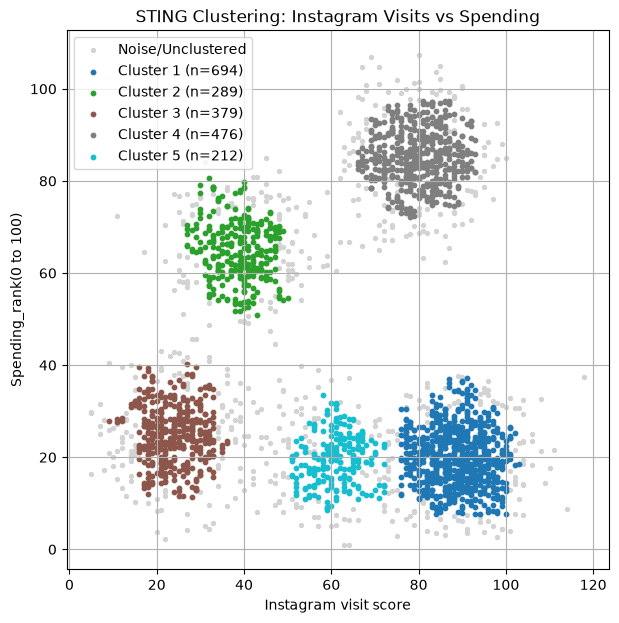

         Instagram visit score  Spending_rank(0 to 100)
cluster                                                
-1                   57.807273                44.725160
 0                   88.740634                20.051967
 1                   38.733564                64.681377
 2                   23.960422                24.885149
 3                   79.899160                85.238972
 4                   61.103774                19.777440
{'count': np.float64(10.0), 'mean': array([-0.00088285, -0.69694244]), 'std': array([0.03386686, 0.03417662]), 'min': array([-0.04980166, -0.7564867 ]), 'max': array([ 0.06308789, -0.65184232])}


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from collections import deque

# -----------------------------
# STING: Statistical Information Grid (2D)
# -----------------------------
class STING:
    """
    Hierarchical grid: layer 0 is 1 cell, layer l has 2^l x 2^l cells,
    and every cell is split into 4 children on the next layer.
    Each cell stores statistics: count, mean, std, min, max.
    """
    def __init__(self, n_levels=5):
        self.n_levels = n_levels

    # ---------- Build the hierarchy (bottom-up) ----------
    def fit(self, X): # Builds the data structure, only has to be done once and can be used to run queries against it. This gives statistics on the cells to compare density
        self.X = X
        self.lo, self.hi = X.min(0), X.max(0) + 1e-9
        L, n = self.n_levels, 2 ** self.n_levels
        ij = np.minimum(((X - self.lo) / (self.hi - self.lo) * n).astype(int), n - 1)
        self.cell_of_point = ij

        # Bottom layer statistics (computed from the points, one pass)
        cnt = np.zeros((n, n)); s = np.zeros((n, n, 2)); ss = np.zeros((n, n, 2))
        mn = np.full((n, n, 2), np.inf); mx = np.full((n, n, 2), -np.inf)
        np.add.at(cnt, (ij[:, 0], ij[:, 1]), 1)
        np.add.at(s,   (ij[:, 0], ij[:, 1]), X)
        np.add.at(ss,  (ij[:, 0], ij[:, 1]), X ** 2)
        np.minimum.at(mn, (ij[:, 0], ij[:, 1]), X)
        np.maximum.at(mx, (ij[:, 0], ij[:, 1]), X)
        self.layers = {L: dict(count=cnt, sum=s, sumsq=ss, min=mn, max=mx)}

        # Each parent aggregates its 4 children (no need to touch the points again)
        for l in range(L - 1, -1, -1):
            c = self.layers[l + 1]; m = 2 ** l
            r = lambda a: a.reshape(m, 2, m, 2, *a.shape[2:])
            self.layers[l] = dict(
                count=r(c['count']).sum((1, 3)),
                sum=r(c['sum']).sum((1, 3)),
                sumsq=r(c['sumsq']).sum((1, 3)),
                min=r(c['min']).min((1, 3)),
                max=r(c['max']).max((1, 3)))
        return self

    def cell_stats(self, level, i, j):
        """Count, mean, std, min, max stored for one cell."""
        c = self.layers[level]; n = c['count'][i, j]
        if n == 0:
            return None
        mean = c['sum'][i, j] / n
        std = np.sqrt(np.maximum(c['sumsq'][i, j] / n - mean ** 2, 0))
        return dict(count=n, mean=mean, std=std, min=c['min'][i, j], max=c['max'][i, j])

    # ---------- Answer the density query (top-down) ----------
    def query(self, min_points=5, start_level=2, min_cluster_size=30): 
        """
        min_points:       a bottom-layer cell is relevant if it has >= min_points points
        start_level:      layer where the top-down search begins
        min_cluster_size: clusters smaller than this are treated as noise
        Returns labels (-1 = noise).
        """
        L = self.n_levels
        relevant = [(i, j) for i in range(2 ** start_level) for j in range(2 ** start_level)]
        self.visited = {}   # layer -> (cells examined, cells kept), shows the pruning

        for l in range(start_level, L + 1):
            cnt = self.layers[l]['count']
            # A cell can only contain a relevant bottom cell if it has >= min_points
            # points, so anything below that is pruned along with all its children.
            keep = [(i, j) for i, j in relevant if cnt[i, j] >= min_points]
            self.visited[l] = (len(relevant), len(keep))
            if l == L:
                relevant = keep
                break
            relevant = [(2 * i + a, 2 * j + b) for i, j in keep for a in (0, 1) for b in (0, 1)]

        # ---------- Merge touching relevant bottom cells into clusters ----------
        dense = set(relevant)
        label_of, k = {}, 0
        for start in dense:
            if start in label_of:
                continue
            label_of[start] = k
            q = deque([start])
            while q:
                i, j = q.popleft()
                for di in (-1, 0, 1):
                    for dj in (-1, 0, 1):
                        nb = (i + di, j + dj)
                        if nb in dense and nb not in label_of:
                            label_of[nb] = k
                            q.append(nb)
            k += 1

        labels = np.array([label_of.get((i, j), -1) for i, j in self.cell_of_point])

        # Drop tiny clusters (treat as noise) and renumber
        sizes = np.bincount(labels[labels >= 0], minlength=k)
        keep_ids = [c for c in range(k) if sizes[c] >= min_cluster_size]
        remap = {c: n for n, c in enumerate(keep_ids)}
        return np.array([remap.get(l, -1) for l in labels])

# -----------------------------
# Load and scale data
# -----------------------------
df = pd.read_csv('ig_clustering.csv', index_col='User ID')
X_raw = df.to_numpy(dtype=float)
X = (X_raw - X_raw.mean(axis=0)) / X_raw.std(axis=0)

# -----------------------------
# Build hierarchy and run the query
# -----------------------------
sting = STING(n_levels=5).fit(X)
labels = sting.query(min_points=5, start_level=2, min_cluster_size=30)
n_clusters = labels.max() + 1
print(f"{n_clusters} clusters, {(labels == -1).sum()} noise points")
print("Cells examined / kept per layer:", sting.visited)

df['cluster'] = labels

# -----------------------------
# Plot (original units)
# -----------------------------
plt.figure(figsize=(7, 7))
noise = labels == -1
plt.scatter(X_raw[noise, 0], X_raw[noise, 1], c='lightgray', s=8, label='Noise/Unclustered')
colors = plt.cm.tab10(np.linspace(0, 1, max(n_clusters, 1)))
for k in range(n_clusters):
    m = labels == k
    plt.scatter(X_raw[m, 0], X_raw[m, 1], color=colors[k], s=10,
                label=f'Cluster {k+1} (n={m.sum()})')
plt.title("STING Clustering: Instagram Visits vs Spending")
plt.xlabel(df.columns[0]); plt.ylabel(df.columns[1])
plt.legend(); plt.grid(True); plt.show()

print(df.groupby('cluster').mean())

# Peek at the statistics stored in one cell (layer 5, cell of the first user)
print(sting.cell_stats(5, *sting.cell_of_point[0]))